# Notebook 8 – Distribution Analysis
## Objective
Analyze the shape, center, spread, skewness, kurtosis, and possible outliers of important numerical features.

**Concepts**
- **Normal:** approximately bell-shaped and symmetric.
- **Uniform:** values are spread relatively evenly over a range.
- **Symmetric:** left and right sides are approximately mirror images.
- **Right-skewed:** longer tail toward larger values; mean is often above median.
- **Left-skewed:** longer tail toward smaller values; mean is often below median.
- **Skewness:** numerical measure of asymmetry.
- **Kurtosis:** tail heaviness relative to normal; pandas reports excess kurtosis, near zero for a normal distribution.

## 1. Load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")
DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
DATA_PATH = Path( r"C:\Users\ramki\sprint_4\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found at {DATA_PATH.resolve()}. Put the CSV beside this notebook or update DATA_PATH.")
df = pd.read_csv(DATA_PATH)
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Shape:", df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Choose important numerical features

In [2]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
important_cols = [c for c in ["tenure", "MonthlyCharges", "TotalCharges"] if c in numeric_cols]
if not important_cols: important_cols = numeric_cols[:5]
print("Features:", important_cols)
display(df[important_cols].describe().T)

Features: ['tenure', 'MonthlyCharges', 'TotalCharges']


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


## 3. Histograms and KDE density curves

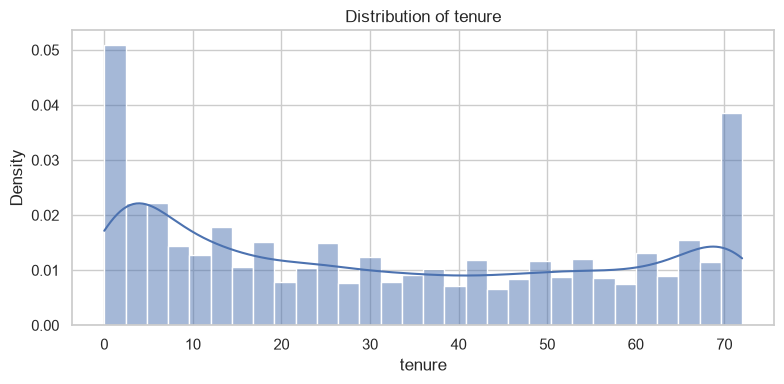

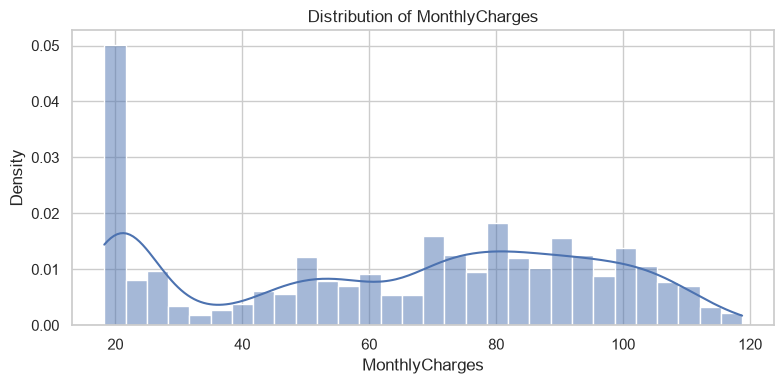

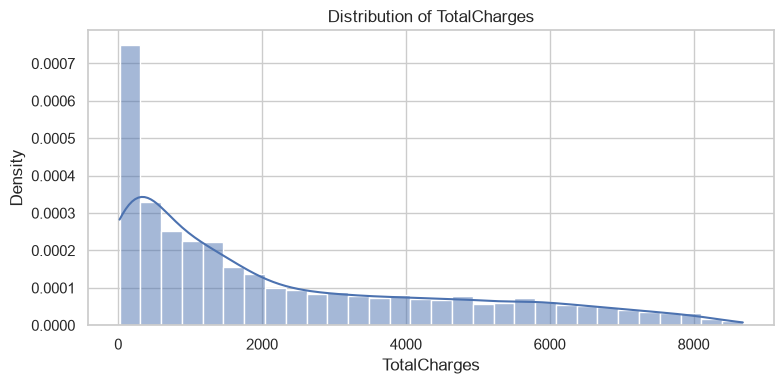

In [3]:
for col in important_cols:
    x = df[col].dropna()
    if x.empty: continue
    plt.figure(figsize=(8, 4))
    sns.histplot(x=x, bins=30, kde=True, stat="density")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()

**Interpretation:** Describe whether the distribution looks symmetric, left-skewed, right-skewed, uniform-like, multi-peaked, or irregular. Do not declare it normal based only on appearance.

## 4. Center, spread, skewness, and kurtosis

In [4]:
rows = []
for col in important_cols:
    x = pd.to_numeric(df[col], errors="coerce").dropna()
    if x.empty: continue
    rows.append({
        "Variable": col, "Count": x.count(), "Mean": x.mean(), "Median": x.median(),
        "Variance": x.var(), "Std deviation": x.std(), "Min": x.min(), "Max": x.max(),
        "Range": x.max()-x.min(), "Q1": x.quantile(.25), "Q3": x.quantile(.75),
        "IQR": x.quantile(.75)-x.quantile(.25), "Skewness": x.skew(),
        "Excess kurtosis": x.kurt()
    })
display(pd.DataFrame(rows).set_index("Variable").round(3))

,Count,Mean,Median,Variance,Std deviation,Min,Max,Range,Q1,Q3,IQR,Skewness,Excess kurtosis
Variable,,,,,,,,,,,,,
tenure,7043,32.371,29.000,603.168,24.559,0.00,72.00,72.0,9.00,55.000,46.000,0.240,-1.387
MonthlyCharges,7043,64.762,70.350,905.411,30.090,18.25,118.75,100.5,35.50,89.850,54.350,-0.221,-1.257
TotalCharges,7032,2283.300,1397.475,5138252.407,2266.771,18.80,8684.80,8666.0,401.45,3794.738,3393.288,0.962,-0.232


## 5. Box plots to inspect spread and potential outliers

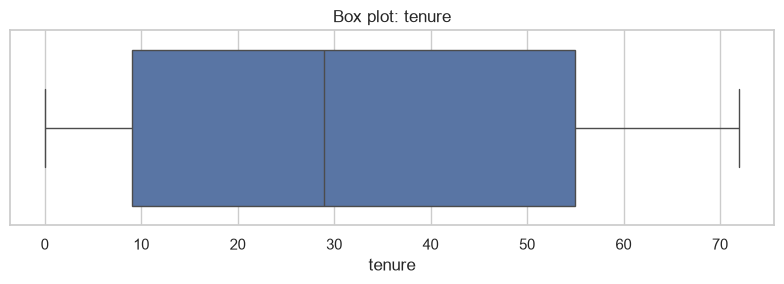

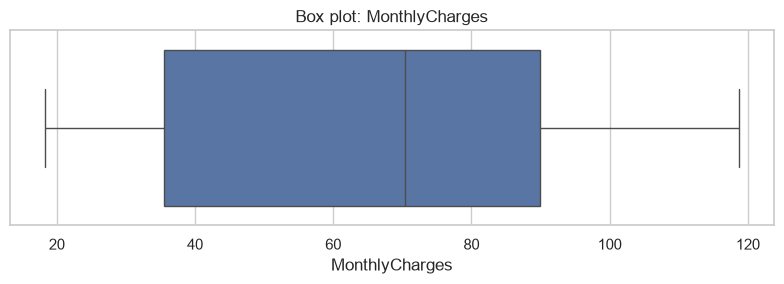

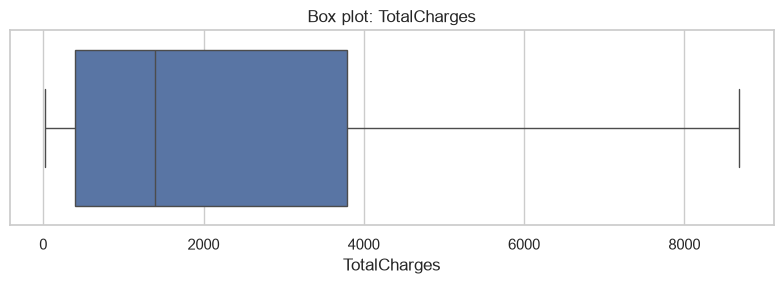

In [5]:
for col in important_cols:
    x = df[col].dropna()
    if x.empty: continue
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=x)
    plt.title(f"Box plot: {col}")
    plt.tight_layout()
    plt.show()

## 6. Reference examples: normal and uniform distributions
These are simulated examples for learning, not assumptions about the dataset.

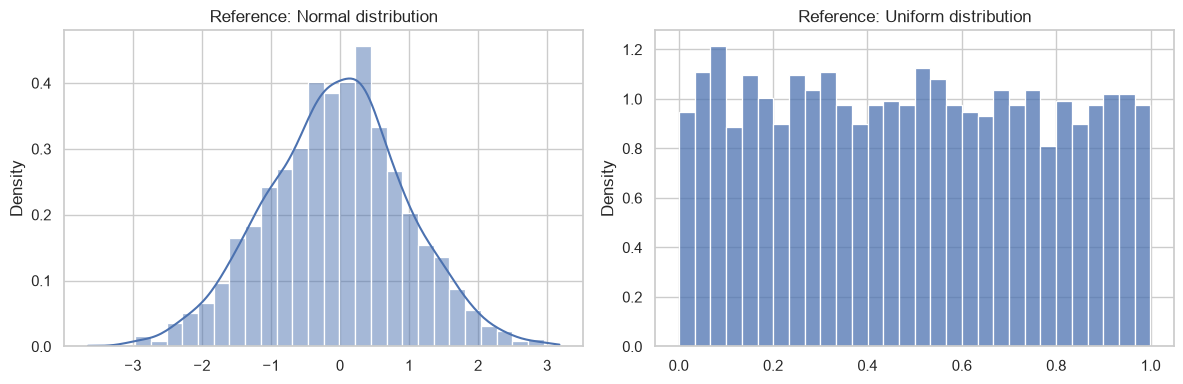

In [6]:
rng = np.random.default_rng(42)
normal_sample = rng.normal(0, 1, 2000)
uniform_sample = rng.uniform(0, 1, 2000)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(normal_sample, bins=30, kde=True, stat="density", ax=axes[0])
axes[0].set_title("Reference: Normal distribution")
sns.histplot(uniform_sample, bins=30, stat="density", ax=axes[1])
axes[1].set_title("Reference: Uniform distribution")
plt.tight_layout()
plt.show()

## 7. Automatic interpretation prompts

In [7]:
for col in important_cols:
    x = df[col].dropna()
    skew = x.skew()
    if skew > .5: shape = "right-skewed"
    elif skew < -.5: shape = "left-skewed"
    else: shape = "approximately symmetric by a simple rule of thumb"
    print(f"\n{col}: {shape}")
    print(f"Center: mean={x.mean():.2f}; median={x.median():.2f}")
    print(f"Spread: std={x.std():.2f}; IQR={x.quantile(.75)-x.quantile(.25):.2f}")
    print(f"Skewness={skew:.2f}; excess kurtosis={x.kurt():.2f}")
    print("Check histogram and box plot before making a final conclusion.")


tenure: approximately symmetric by a simple rule of thumb
Center: mean=32.37; median=29.00
Spread: std=24.56; IQR=46.00
Skewness=0.24; excess kurtosis=-1.39
Check histogram and box plot before making a final conclusion.

MonthlyCharges: approximately symmetric by a simple rule of thumb
Center: mean=64.76; median=70.35
Spread: std=30.09; IQR=54.35
Skewness=-0.22; excess kurtosis=-1.26
Check histogram and box plot before making a final conclusion.

TotalCharges: right-skewed
Center: mean=2283.30; median=1397.47
Spread: std=2266.77; IQR=3393.29
Skewness=0.96; excess kurtosis=-0.23
Check histogram and box plot before making a final conclusion.


## 8. Findings and conclusion
For each feature, describe:
- **Shape:** symmetric, skewed, uniform-like, multi-peaked, or irregular.
- **Center:** mean and median.
- **Spread:** standard deviation, range, and IQR.
- **Skewness and kurtosis:** report values and interpret cautiously.
- **Outliers:** whether the box plot shows potential extremes.

**Conclusion:** Distribution analysis helps understand how data behaves and whether robust summaries or transformations may be worth considering.